# iTransformer: Inverted Transformers for Time Series Forecasting

**Paper**: Yong Liu, Tengge Hu, Haoran Zhang, Haixu Wu, Shiyu Wang, Lintao Ma, Mingsheng Long. *iTransformer: Inverted Transformers Are Effective for Time Series Forecasting.* ICLR 2024 (Spotlight). [arXiv:2310.06625](https://arxiv.org/abs/2310.06625)

**Official code**: [github.com/thuml/iTransformer](https://github.com/thuml/iTransformer)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/itransformer_inverted.ipynb)

**Key ideas**:
- **Invert the token axis**: a vanilla Transformer makes one token per *time step* (mixing all variates measured at that instant). iTransformer makes one token per **variate**: the variate's *whole look-back series* `x[:, c] ∈ R^L` is embedded by a linear layer into a `d_model` vector.
- **Attention across variates**: self-attention now mixes information *between channels* (multivariate correlations), and the attention map is interpretable as a learned channel-correlation matrix.
- **FFN per variate token**: the feed-forward network and LayerNorm act on each variate's series representation, learning temporal features.
- **Non-stationary normalisation** (from Non-stationary Transformer / RevIN): each input window is standardised per variate and the forecast is de-normalised with the same statistics.
- **Linear projection** of each variate token `d_model → H` gives the whole horizon at once; no decoder.
- Timestamp covariates (hour/day features) are simply appended as **extra tokens**, and their outputs are dropped.

This notebook implements iTransformer from scratch in PyTorch, faithfully to `model/iTransformer.py`, `layers/` and the ETTh1 script `scripts/multivariate_forecasting/ETT/iTransformer_ETTh1.sh`, and evaluates it on **ETTh1, multivariate (7 channels), L = 96 → H = 96**.

## Setup

Everything needed (PyTorch, NumPy, pandas, scikit-learn, matplotlib) is pre-installed on Colab, so there is nothing to `pip install`.

In [1]:
import os, time, json, random, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

torch 2.12.1+cu130 | device: cuda | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## Data: ETTh1 with the standard splits + timestamp features

Standard Informer/Autoformer/TSLib borders: train `[0, 8640)`, val `[8640 − L, 11520)`, test `[11520 − L, 14400)`; `StandardScaler` fit on train rows only; metrics in the scaled space; test windows slide with stride 1 → **2785 windows**.

The official data loader (`embed='timeF'`, `freq='h'`) also returns 4 calendar features for every input step, which iTransformer appends as extra variate tokens:

$$\text{HourOfDay} = \tfrac{h}{23}-0.5,\quad \text{DayOfWeek} = \tfrac{d_w}{6}-0.5,\quad \text{DayOfMonth} = \tfrac{d_m-1}{30}-0.5,\quad \text{DayOfYear} = \tfrac{d_y-1}{365}-0.5 .$$

We keep the shared `load_etth1` / `WindowDataset` helpers unchanged and add a small wrapper that also returns these features for the look-back window.

In [2]:
import numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])


def load_time_marks(lookback):
    """Calendar features (TSLib timeF, freq='h'), sliced exactly like load_etth1."""
    d = pd.to_datetime(pd.read_csv(URL, usecols=["date"])["date"])
    marks = np.stack([d.dt.hour / 23.0 - 0.5,
                      d.dt.dayofweek / 6.0 - 0.5,
                      (d.dt.day - 1) / 30.0 - 0.5,
                      (d.dt.dayofyear - 1) / 365.0 - 0.5], axis=1).astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    return (marks[:n_tr], marks[n_tr - lookback: n_tr + n_va],
            marks[n_tr + n_va - lookback: n_tr + n_va + n_te])


class WindowDatasetMark(WindowDataset):
    """WindowDataset that additionally returns the look-back timestamp features."""
    def __init__(self, arr, marks, L, H, stride=1):
        super().__init__(arr, L, H, stride)
        self.marks = marks
    def __getitem__(self, k):
        x, y = super().__getitem__(k)
        i = self.idx[k]
        return x, y, torch.from_numpy(self.marks[i:i+self.L])


L, H = 96, 96
train_arr, val_arr, test_arr, cols = load_etth1(L)
train_mk, val_mk, test_mk = load_time_marks(L)
print("channels:", cols)
print("train/val/test rows:", train_arr.shape, val_arr.shape, test_arr.shape, "| time features:", train_mk.shape[1])
print("test windows:", len(WindowDatasetMark(test_arr, test_mk, L, H)))

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
train/val/test rows: (8640, 7) (2976, 7) (2976, 7) | time features: 4
test windows: 2785


## Component 1: inverted embedding (one token per variate)

Given $X \in \mathbb{R}^{L \times N}$ (look-back × variates) and timestamp features $M \in \mathbb{R}^{L \times 4}$, transpose to variate-major order, concatenate, and embed every length-$L$ series with one shared linear layer:

$$h_n^{0} = \mathrm{Dropout}\big(W_e\, x_{:,n} + b_e\big) \in \mathbb{R}^{D}, \qquad n = 1..N+4 .$$

So ETTh1 becomes a sequence of only **11 tokens** (7 variates + 4 time features). There is **no positional encoding**: the order of variates carries no meaning, and the temporal order is already encoded inside each token by the linear layer.

In [3]:
class DataEmbeddingInverted(nn.Module):
    def __init__(self, seq_len, d_model, dropout=0.1):
        super().__init__()
        self.value_embedding = nn.Linear(seq_len, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, x_mark):              # x: [B, L, N], x_mark: [B, L, 4] or None
        x = x.permute(0, 2, 1)                 # [B, N, L]
        if x_mark is not None:
            x = torch.cat([x, x_mark.permute(0, 2, 1)], 1)   # [B, N+4, L]
        return self.dropout(self.value_embedding(x))         # [B, N+4, D]

## Component 2: a standard Transformer encoder, applied across variates

Each of the `e_layers` encoder layers is the vanilla post-LN block (as in `layers/Transformer_EncDec.py`):

$$\tilde H = \mathrm{LayerNorm}\big(H + \mathrm{Dropout}(\mathrm{MHA}(H,H,H))\big), \qquad H' = \mathrm{LayerNorm}\big(\tilde H + \mathrm{FFN}(\tilde H)\big),$$

with full (un-masked) scaled dot-product attention $\mathrm{softmax}(QK^\top/\sqrt{d_k})V$ over the **variate tokens**, and a position-wise FFN implemented as two 1×1 convolutions with GELU (`d_model → d_ff → d_model`). A final LayerNorm closes the encoder. The attention matrix $A \in \mathbb{R}^{(N+4)\times(N+4)}$ shows which channels each channel draws information from.

In [4]:
class FullAttention(nn.Module):
    def __init__(self, attention_dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(attention_dropout)

    def forward(self, q, k, v):                     # [B, T, Hh, E]
        scale = 1.0 / math.sqrt(q.shape[-1])
        scores = torch.einsum("blhe,bshe->bhls", q, k)
        A = self.dropout(torch.softmax(scale * scores, dim=-1))
        return torch.einsum("bhls,bshd->blhd", A, v).contiguous(), A


class AttentionLayer(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        d_k = d_model // n_heads
        self.inner = FullAttention(dropout)
        self.query_projection = nn.Linear(d_model, d_k * n_heads)
        self.key_projection = nn.Linear(d_model, d_k * n_heads)
        self.value_projection = nn.Linear(d_model, d_k * n_heads)
        self.out_projection = nn.Linear(d_k * n_heads, d_model)
        self.n_heads = n_heads

    def forward(self, x):
        B, T, _ = x.shape
        q = self.query_projection(x).view(B, T, self.n_heads, -1)
        k = self.key_projection(x).view(B, T, self.n_heads, -1)
        v = self.value_projection(x).view(B, T, self.n_heads, -1)
        out, A = self.inner(q, k, v)
        return self.out_projection(out.view(B, T, -1)), A


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1, activation="gelu"):
        super().__init__()
        self.attention = AttentionLayer(d_model, n_heads, dropout)
        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.gelu if activation == "gelu" else F.relu

    def forward(self, x):
        new_x, A = self.attention(x)
        x = x + self.dropout(new_x)
        y = x = self.norm1(x)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))
        return self.norm2(x + y), A


class Encoder(nn.Module):
    def __init__(self, layers, d_model):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        attns = []
        for layer in self.layers:
            x, A = layer(x)
            attns.append(A)
        return self.norm(x), attns

## Component 3: iTransformer = normalise → invert-embed → encode → project → de-normalise

1. **Non-stationary normalisation** per window and variate: $\mu = \text{mean}_t\, x$, $\sigma = \sqrt{\text{Var}_t\, x + 10^{-5}}$, $x \leftarrow (x-\mu)/\sigma$ (mean detached, as in the official code).
2. Inverted embedding → $(N+4)$ tokens.
3. `e_layers` encoder layers with attention across variates.
4. **Projection** $W_p \in \mathbb{R}^{H \times D}$ maps every token to the full horizon; keep the first $N$ (real variates), drop the timestamp tokens.
5. De-normalise: $\hat y = \hat y \cdot \sigma + \mu$.

ETTh1 96→96 hyper-parameters from the official script `iTransformer_ETTh1.sh`: `e_layers=2`, `d_model=256`, `d_ff=256`, and the `run.py` defaults `n_heads=8`, `dropout=0.1`, `activation=gelu`, `use_norm=True`.

In [5]:
class ITransformer(nn.Module):
    def __init__(self, seq_len, pred_len, d_model=256, n_heads=8, e_layers=2, d_ff=256,
                 dropout=0.1, activation="gelu", use_norm=True):
        super().__init__()
        self.pred_len, self.use_norm = pred_len, use_norm
        self.enc_embedding = DataEmbeddingInverted(seq_len, d_model, dropout)
        self.encoder = Encoder([EncoderLayer(d_model, n_heads, d_ff, dropout, activation)
                                for _ in range(e_layers)], d_model)
        self.projector = nn.Linear(d_model, pred_len, bias=True)

    def forward(self, x_enc, x_mark=None, return_attn=False):   # x_enc: [B, L, N]
        if self.use_norm:
            means = x_enc.mean(1, keepdim=True).detach()
            x_enc = x_enc - means
            stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
            x_enc = x_enc / stdev
        N = x_enc.shape[2]
        enc_out = self.enc_embedding(x_enc, x_mark)              # [B, N+4, D]
        enc_out, attns = self.encoder(enc_out)                   # [B, N+4, D]
        dec_out = self.projector(enc_out).permute(0, 2, 1)[:, :, :N]   # [B, H, N]
        if self.use_norm:
            dec_out = dec_out * stdev[:, 0, :].unsqueeze(1) + means[:, 0, :].unsqueeze(1)
        return (dec_out, attns) if return_attn else dec_out


CFG = dict(d_model=256, n_heads=8, e_layers=2, d_ff=256, dropout=0.1, activation="gelu", use_norm=True)
m = ITransformer(L, H, **CFG)
print("output shape:", m(torch.randn(4, L, len(cols)), torch.randn(4, L, 4)).shape)
print("params:", sum(p.numel() for p in m.parameters()))

output shape: torch.Size([4, 96, 7])
params: 841568


## Training recipe (from `run.py` + `experiments/exp_long_term_forecasting.py`)

| setting | value |
|---|---|
| loss | MSE |
| optimizer | Adam, `lr = 1e-4` |
| batch size | 32, shuffled, `drop_last=True` |
| epochs | 10 max, early stopping on validation MSE with patience 3, best checkpoint restored |
| LR schedule | `type1`: halve the LR after every epoch |

In [6]:
def make_loaders(batch_size=32):
    g = torch.Generator().manual_seed(SEED)
    tr = torch.utils.data.DataLoader(WindowDatasetMark(train_arr, train_mk, L, H), batch_size=batch_size,
                                     shuffle=True, drop_last=True, generator=g)
    va = torch.utils.data.DataLoader(WindowDatasetMark(val_arr, val_mk, L, H), batch_size=256, shuffle=False)
    te = torch.utils.data.DataLoader(WindowDatasetMark(test_arr, test_mk, L, H), batch_size=256, shuffle=False)
    return tr, va, te


@torch.no_grad()
def evaluate(model, loader, return_preds=False):
    model.eval()
    se = ae = n = 0.0
    preds = []
    for x, y, xm in loader:
        x, y, xm = x.to(device), y.to(device), xm.to(device)
        p = model(x, xm)
        se += ((p - y) ** 2).sum().item(); ae += (p - y).abs().sum().item(); n += y.numel()
        if return_preds: preds.append(p.cpu())
    out = (se / n, ae / n)
    return out + (torch.cat(preds).numpy(),) if return_preds else out


def train_model(model, tr, va, te, lr=1e-4, epochs=10, patience=3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    best, best_state, bad = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); losses = []
        for x, y, xm in tr:
            x, y, xm = x.to(device), y.to(device), xm.to(device)
            opt.zero_grad()
            loss = crit(model(x, xm), y)
            loss.backward(); opt.step()
            losses.append(loss.item())
        v_mse, _ = evaluate(model, va); t_mse, _ = evaluate(model, te)
        print(f"epoch {ep:2d} | lr {opt.param_groups[0]['lr']:.2e} | train {np.mean(losses):.4f} "
              f"| val {v_mse:.4f} | test {t_mse:.4f} | {time.time()-t0:.1f}s")
        if v_mse < best:
            best, bad = v_mse, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
        for g in opt.param_groups:                       # lradj = type1
            g["lr"] = lr * 0.5 ** ep
    model.load_state_dict(best_state)
    return model

## Train iTransformer on ETTh1 (L = 96 → H = 96)

In [7]:
seed_everything()
tr_loader, va_loader, te_loader = make_loaders()
model = ITransformer(L, H, **CFG).to(device)
n_params = sum(p.numel() for p in model.parameters())
t_start = time.time()
model = train_model(model, tr_loader, va_loader, te_loader, lr=1e-4)
train_seconds = time.time() - t_start
test_mse, test_mae, test_pred = evaluate(model, te_loader, return_preds=True)
print(f"\niTransformer | test MSE {test_mse:.4f} | test MAE {test_mae:.4f} | {n_params:,} params | {train_seconds:.1f}s")

epoch  1 | lr 1.00e-04 | train 0.4181 | val 0.7078 | test 0.4006 | 1.9s


epoch  2 | lr 5.00e-05 | train 0.3701 | val 0.7006 | test 0.3911 | 1.6s


epoch  3 | lr 2.50e-05 | train 0.3622 | val 0.6899 | test 0.3897 | 1.6s


epoch  4 | lr 1.25e-05 | train 0.3585 | val 0.6869 | test 0.3886 | 1.6s


epoch  5 | lr 6.25e-06 | train 0.3565 | val 0.6855 | test 0.3890 | 1.6s


epoch  6 | lr 3.13e-06 | train 0.3554 | val 0.6842 | test 0.3888 | 1.6s


epoch  7 | lr 1.56e-06 | train 0.3550 | val 0.6840 | test 0.3886 | 1.6s


epoch  8 | lr 7.81e-07 | train 0.3548 | val 0.6839 | test 0.3886 | 1.6s


epoch  9 | lr 3.91e-07 | train 0.3546 | val 0.6838 | test 0.3886 | 1.6s


epoch 10 | lr 1.95e-07 | train 0.3546 | val 0.6838 | test 0.3886 | 1.6s

iTransformer | test MSE 0.3886 | test MAE 0.4042 | 841,568 params | 17.2s


## Forecast plot (OT channel)

History (look-back), ground truth and iTransformer forecast for a few test windows, in the scaled space.

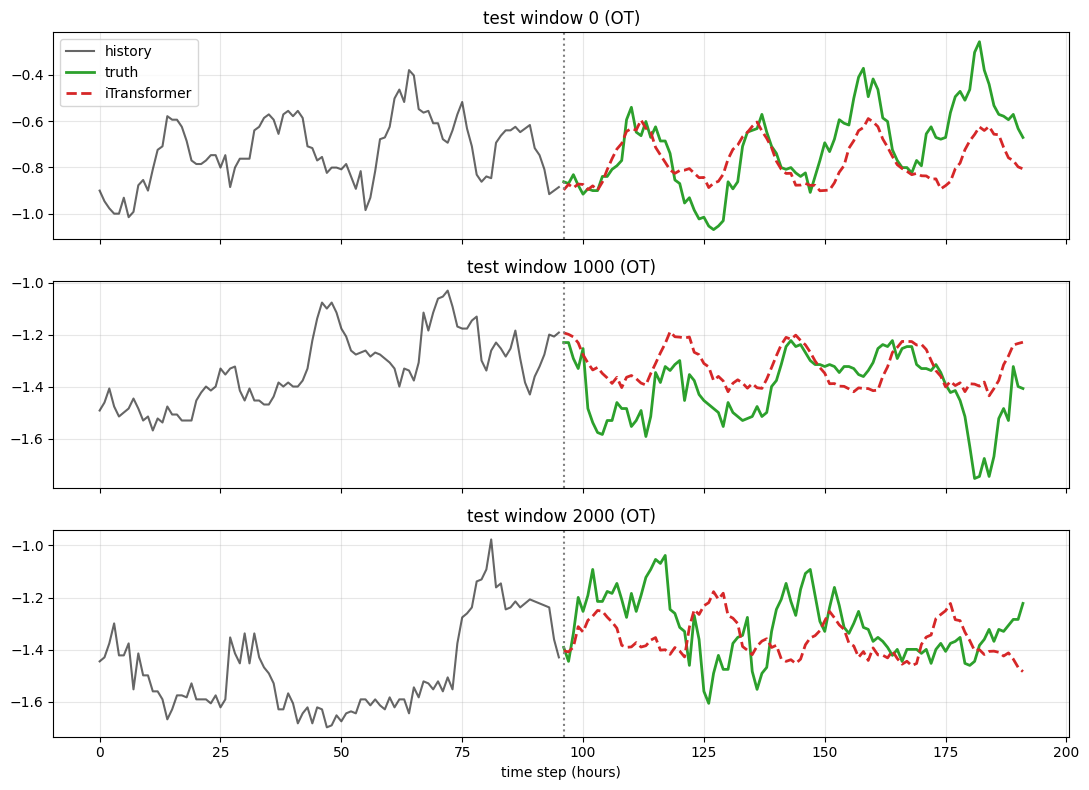

In [8]:
te_ds = te_loader.dataset
ot = cols.index("OT")
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, k in zip(axes, [0, 1000, 2000]):
    x, y, _ = te_ds[k]
    ax.plot(np.arange(L), x[:, ot], color="k", alpha=0.6, label="history")
    ax.plot(np.arange(L, L + H), y[:, ot], color="tab:green", lw=2, label="truth")
    ax.plot(np.arange(L, L + H), test_pred[k, :, ot], "--", color="tab:red", lw=2, label="iTransformer")
    ax.axvline(L, color="gray", ls=":"); ax.set_title(f"test window {k} (OT)"); ax.grid(alpha=0.3)
axes[0].legend(loc="upper left"); axes[-1].set_xlabel("time step (hours)")
plt.tight_layout(); plt.show()

## Attention across variates

The inverted design makes the attention map a *variate × variate* matrix. Below: the last encoder layer's attention, averaged over heads and over all test windows. Rows are queries ("which channel is being updated"), columns are keys ("which channel it reads from"); the last 4 tokens are the timestamp features.

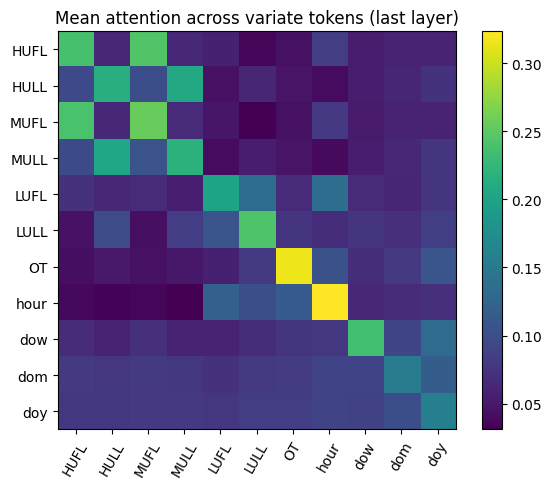

In [9]:
model.eval()
A_sum, cnt = 0, 0
with torch.no_grad():
    for x, y, xm in te_loader:
        _, attns = model(x.to(device), xm.to(device), return_attn=True)
        A_sum = A_sum + attns[-1].mean(1).sum(0).cpu(); cnt += x.shape[0]
A_mean = (A_sum / cnt).numpy()
labels = cols + ["hour", "dow", "dom", "doy"]
plt.figure(figsize=(6, 5))
plt.imshow(A_mean, cmap="viridis"); plt.colorbar(fraction=0.046)
plt.xticks(range(len(labels)), labels, rotation=60); plt.yticks(range(len(labels)), labels)
plt.title("Mean attention across variate tokens (last layer)"); plt.tight_layout(); plt.show()

## Results

Reference: iTransformer paper (ICLR 2024, full long-term forecasting results in the appendix), ETTh1, L = 96, H = 96: **MSE 0.386, MAE 0.405**.

In [10]:
PAPER_MSE, PAPER_MAE = 0.386, 0.405
print(f"{'model':<22}{'MSE':>8}{'MAE':>8}   {'paper MSE':>10}{'paper MAE':>10}")
print(f"{'iTransformer (ours)':<22}{test_mse:8.4f}{test_mae:8.4f}   {PAPER_MSE:10.3f}{PAPER_MAE:10.3f}")
print(f"\nparams: {n_params:,} | train time: {train_seconds:.1f} s | device: {device}")

results = {
    "model": "iTransformer",
    "paper": "iTransformer: Inverted Transformers Are Effective for Time Series Forecasting (Liu et al.)",
    "venue": "ICLR 2024 (Spotlight)",
    "type": "supervised",
    "lookback": L, "horizon": H,
    "mse": round(test_mse, 4), "mae": round(test_mae, 4),
    "paper_mse": PAPER_MSE, "paper_mae": PAPER_MAE,
    "params": n_params,
    "train_or_infer_seconds": round(train_seconds, 1),
    "notes": ("From-scratch iTransformer following thuml/iTransformer: e_layers=2, d_model=256, d_ff=256 "
              "(iTransformer_ETTh1.sh), n_heads=8, dropout=0.1, gelu, use_norm=True, 4 timeF calendar features "
              "as extra variate tokens; Adam lr 1e-4, bs 32, MSE loss, 10 epochs max, patience 3, lr halved each epoch. "
              "Test: all 2785 stride-1 windows."),
}
try:
    with open("results_itransformer_inverted.json", "w") as f:
        json.dump(results, f, indent=2)
    print("wrote results_itransformer_inverted.json")
except Exception as e:
    print("could not write results JSON:", e)

model                      MSE     MAE    paper MSE paper MAE
iTransformer (ours)     0.3886  0.4042        0.386     0.405

params: 841,568 | train time: 17.2 s | device: cuda
wrote results_itransformer_inverted.json


## Using your own data

1. Load a `(T, N)` float array, split chronologically, fit a `StandardScaler` on the training part only, and build windows:
   ```python
   df = pd.read_csv("my_series.csv", parse_dates=["date"])
   data = df.drop(columns=["date"]).values.astype(np.float32)
   n_tr, n_va = int(0.7 * len(data)), int(0.1 * len(data))
   scaler = StandardScaler().fit(data[:n_tr]); data = scaler.transform(data).astype(np.float32)
   train_arr, val_arr, test_arr = data[:n_tr], data[n_tr - L:n_tr + n_va], data[n_tr + n_va - L:]
   ```
   Build matching calendar features (as in `load_time_marks`) for `WindowDatasetMark`, or pass `x_mark=None` to the model to use the series alone (the official code does this for PEMS/Solar).
2. Instantiate `ITransformer(seq_len=L, pred_len=H, **CFG)`; the number of variates is **not** a constructor argument, so the same model works for any `N` (even different `N` at test time, which the paper uses for generalisation to unseen variates).
3. Tips:
   - Cost grows with `N²` (attention over variates) and linearly with `L`, so iTransformer scales well to long look-backs, and longer `L` usually helps.
   - For datasets with many variates (Traffic, Electricity) the paper uses `d_model = d_ff = 512`, `e_layers = 3–4`; for small ones like ETT, `256` and 2 layers.
   - Keep `use_norm=True` for non-stationary series; invert the scaling with `scaler.inverse_transform` for original units.